# Лабораторная работа: гиперболическое уравнение

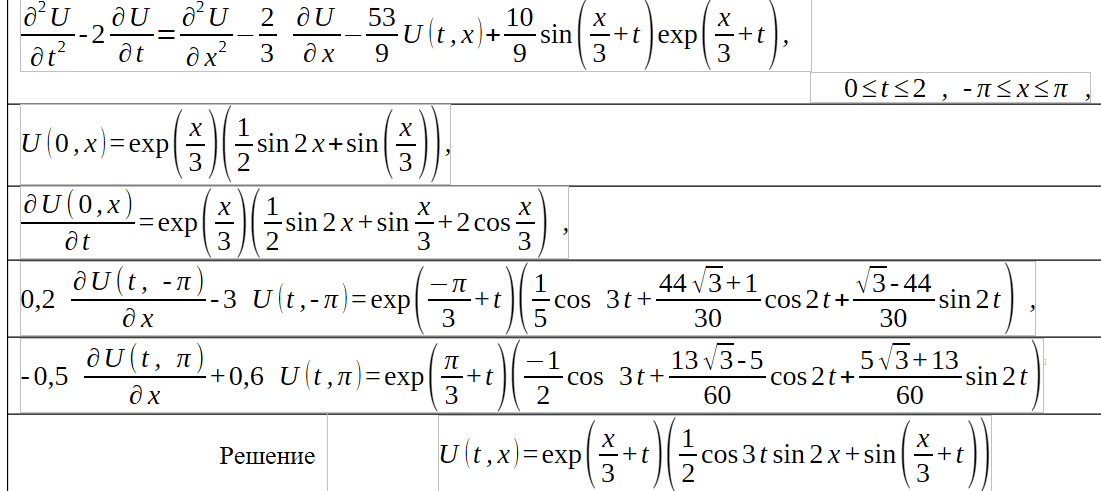

## Конечно-разностная схема

Рассматривается общее гиперболическое уравнение

$$\frac{\partial^2u}{\partial t^2}+e\frac{\partial u}{\partial t}=a^2\frac{\partial^2u}{\partial x^2}+b\frac{\partial u}{\partial x}+cu+f(x,t).$$

Для нашей задачи $a=1$, $b=-2/3$, $c=-53/9$, $e=-2$,

$$f(x,t)=\frac{10}{9}e^{x/3+t}\sin\left(\frac{x}{3}+2t\right).$$

Введём сетку:

$$x_j=x_0+jh,\quad j=0,1,\ldots,N,\qquad t_n=n\tau,\quad n=0,1,\ldots$$

Полная разностная аппроксимация второго порядка имеет вид

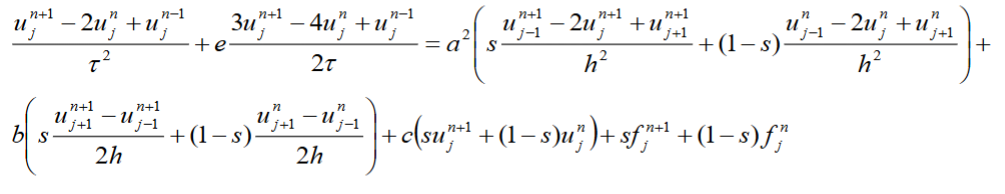

Здесь формула для $u_{tt}$ использует слои $n+1,n,n-1$, а первая производная аппроксимируется именно трёхточечной формулой

$$u_t\approx\frac{3u_j^{n+1}-4u_j^n+u_j^{n-1}}{2\tau}.$$

Пространственные производные, само решение и правая часть берутся как взвешенная сумма слоёв $n+1$ и $n$ с весами $s$ и $1-s$.

$s=0$ — явная схема, $s=1$ — неявная, $0<s<1$ — полунеявная. В работе для полунеявной схемы берётся $s=1/2$.

Сокращение, введённое только для удобства программы.

$$L_hv_j=\left(\frac{a^2}{h^2}-\frac{b}{2h}\right)v_{j-1}+\left(-\frac{2a^2}{h^2}+c\right)v_j+\left(\frac{a^2}{h^2}+\frac{b}{2h}\right)v_{j+1}.$$

Поэтому та же схема в коде короче записывается как

$$\frac{u_j^{n+1}-2u_j^n+u_j^{n-1}}{\tau^2}+e\frac{3u_j^{n+1}-4u_j^n+u_j^{n-1}}{2\tau}=sL_hu_j^{n+1}+(1-s)L_hu_j^n+sf_j^{n+1}+(1-s)f_j^n.$$


In [1]:
from math import cos, exp, pi, sin, sqrt
import matplotlib.pyplot as plt

# Коэффициенты уравнения.
a = 1.0
b = -2/3
c = -53/9
e = -2.0

# Коэффициенты граничных условий третьего рода.
alpha = 0.2
beta = -3.0
gamma = -0.5
delta = 0.6

# Расчётная область и шаги сетки. xk — это правая граница l.
x0 = -pi
xk = pi
T = 2.0
# N — число интервалов; узлов N + 1 = 81.
N = 80
h = (xk - x0)/N
tau = 0.005           # 0.005
times_to_show = [0.0, 0.4, 0.8, 1.2, 1.6, 2.0]
# Более частые моменты нужны только для гладких графиков норм.
error_time_step = 0.02
error_times = [round(k*error_time_step, 10)
               for k in range(round(T/error_time_step) + 1)]

def f(x, t):
    return 10*exp(x/3 + t)*sin(x/3 + 2*t)/9

def psi_1(x):
    # Начальное смещение u(x, 0).
    return exp(x/3)*(sin(2*x)/2 + sin(x/3))

def psi_2(x):
    # Начальная скорость u_t(x, 0).
    return exp(x/3)*(sin(2*x)/2 + sin(x/3) + 2*cos(x/3))

def psi_1_prime(x):
    g = sin(2*x)/2 + sin(x/3)
    g_prime = cos(2*x) + cos(x/3)/3
    return exp(x/3)*(g/3 + g_prime)

def psi_1_second(x):
    g = sin(2*x)/2 + sin(x/3)
    g_prime = cos(2*x) + cos(x/3)/3
    g_second = -2*sin(2*x) - sin(x/3)/9
    return exp(x/3)*(g/9 + 2*g_prime/3 + g_second)

def phi_left(t):
    return exp(-pi/3 + t)*(
        cos(3*t)/5
        + (44*sqrt(3) + 1)*cos(2*t)/30
        + (sqrt(3) - 44)*sin(2*t)/30
    )

def phi_right(t):
    return exp(pi/3 + t)*(
        -cos(3*t)/2
        + (13*sqrt(3) - 5)*cos(2*t)/60
        + (5*sqrt(3) + 13)*sin(2*t)/60
    )

def exact_solution(x, t):
    return exp(x/3 + t)*(
        cos(3*t)*sin(2*x)/2 + sin(x/3 + 2*t)
    )

## Граничные условия

В задаче заданы неоднородные условия третьего рода:

$$0.2u_x(t,-\pi)-3u(t,-\pi)=\varphi_0(t),$$

$$-0.5u_x(t,\pi)+0.6u(t,\pi)=\varphi_l(t).$$

То есть $\alpha=0.2$, $\beta=-3$, $\gamma=-0.5$, $\delta=0.6$. Функции $\varphi_0(t)$ и $\varphi_l(t)$ записаны в коде как phi_left и phi_right.

Граничные условия аппроксимируются со вторым порядком. После исключения $u_{xx}$ через исходное уравнение левая строка системы имеет вид

$$B_0u_0^{n+1}+C_0u_1^{n+1}=D_0,$$

$$B_0=\frac{2a^2\alpha}{h}\left(1+\frac{h^2}{2a^2\tau^2}\left(1+\frac{3e\tau}{2}-c\tau^2\right)\right)-\beta(2a^2-hb),$$

$$C_0=-\frac{2a^2\alpha}{h},$$

$$D_0=\frac{\alpha h}{\tau^2}\left(2(1+e\tau)u_0^n-\left(1+\frac{e\tau}{2}\right)u_0^{n-1}+\tau^2f_0^{n+1}\right)-(2a^2-hb)\varphi_0^{n+1}.$$

Правая строка записывается как

$$A_Nu_{N-1}^{n+1}+B_Nu_N^{n+1}=D_N,$$

$$A_N=-\frac{2a^2\gamma}{h},$$

$$B_N=\frac{2a^2\gamma}{h}\left(1+\frac{h^2}{2a^2\tau^2}\left(1+\frac{3e\tau}{2}-c\tau^2\right)\right)+\delta(2a^2+hb),$$

$$D_N=\frac{\gamma h}{\tau^2}\left(2(1+e\tau)u_N^n-\left(1+\frac{e\tau}{2}\right)u_N^{n-1}+\tau^2f_N^{n+1}\right)+(2a^2+hb)\varphi_l^{n+1}.$$

## Начальные условия и первые два временных слоя

Должны быть заданы два начальных условия

$$u(x,0)=\psi_1(x),\qquad u_t(x,0)=\psi_2(x).$$

Это связано со второй производной по времени: чтобы начать трёхслойную схему, нужны значения $u^0$ и $u^1$. Нулевой слой задаётся точно:

$$u_j^0=\psi_1(x_j).$$

Для первого слоя раскладываем решение по времени в ряд Тейлора и выражаем $u_{tt}(x,0)$ из исходного уравнения:

$$u_j^1=\psi_1(x_j)+\tau\psi_2(x_j)+\frac{\tau^2}{2}\left(a^2\psi_1''(x_j)+b\psi_1'(x_j)+c\psi_1(x_j)+f(x_j,0)-e\psi_2(x_j)\right).$$

Так первый слой имеет второй порядок аппроксимации по $\tau$.

Имя, введённое только для удобства программы. Выражение в круглых скобках - это начальное ускорение $u_{tt}(x_j,0)$. В коде оно временно сохраняется в переменной acceleration, чтобы длинная формула читалась по частям.

In [2]:
def first_two_layers(x_grid):
    u_0 = [psi_1(x) for x in x_grid]
    u_1 = [0.0]*(N + 1)

    for j in range(N + 1):
        x = x_grid[j]
        # acceleration — правая часть формулы для u_tt(x, 0).
        acceleration = (
            a**2*psi_1_second(x)
            + b*psi_1_prime(x)
            + c*psi_1(x)
            + f(x, 0.0)
            - e*psi_2(x)
        )
        u_1[j] = psi_1(x) + tau*psi_2(x) + tau**2*acceleration/2

    return u_0, u_1

In [3]:
def progonka(A, B, C, D):
    # A, B, C — нижняя, главная и верхняя диагонали; D — правая часть.
    size = len(D)
    P = [0.0]*size
    Q = [0.0]*size

    P[0] = -C[0]/B[0]
    Q[0] = D[0]/B[0]

    for j in range(1, size):
        denominator = B[j] + A[j]*P[j - 1]
        P[j] = -C[j]/denominator
        Q[j] = (D[j] - A[j]*Q[j - 1])/denominator

    u = [0.0]*size
    u[-1] = Q[-1]
    for j in range(size - 2, -1, -1):
        u[j] = P[j]*u[j + 1] + Q[j]

    return u

### Итоговая система для следующего временного слоя

Переносим все неизвестные значения слоя $n+1$ в левую часть. Для каждого внутреннего узла получается трёхдиагональное уравнение

$$A_j u_{j-1}^{n+1}+B_j u_j^{n+1}+C_j u_{j+1}^{n+1}=D_j,$$

где коэффициенты, полученные непосредственно из полной разностной схемы, равны

$$A_j=-s\tau^2\left(\frac{a^2}{h^2}-\frac{b}{2h}\right),$$

$$B_j=1+\frac{3e\tau}{2}+s\tau^2\left(\frac{2a^2}{h^2}-c\right),$$

$$C_j=-s\tau^2\left(\frac{a^2}{h^2}+\frac{b}{2h}\right),$$

$$D_j=(2+2e\tau)u_j^n-\left(1+\frac{e\tau}{2}\right)u_j^{n-1}+\tau^2\left((1-s)L_hu_j^n+sf_j^{n+1}+(1-s)f_j^n\right).$$

В коде три коэффициента пространственного оператора называются l_minus, l_center, l_plus:

$$l_-=\frac{a^2}{h^2}-\frac{b}{2h},\qquad l_0=-\frac{2a^2}{h^2}+c,\qquad l_+=\frac{a^2}{h^2}+\frac{b}{2h}.$$

Поэтому код пишет $A_j=-s\tau^2l_-$, $B_j=1+3e\tau/2-s\tau^2l_0$, $C_j=-s\tau^2l_+$. Переменная L_n — это $L_hu_j^n$.

In [4]:
# spatial_operator вычисляет сокращение L_h
def spatial_operator(u, j):
    u_x = (u[j + 1] - u[j - 1])/(2*h)
    u_xx = (u[j - 1] - 2*u[j] + u[j + 1])/h**2
    return a**2*u_xx + b*u_x + c*u[j]

def scheme_step(u_n_minus_1, u_n, x_grid, t_n, s):
    # s = 0 — явная, s = 1 — неявная, s = 0.5 — полунеявная.
    t_n_plus_1 = t_n + tau

    # l_minus, l_center, l_plus — три коэффициента оператора L_h.
    l_minus = a**2/h**2 - b/(2*h)
    l_center = -2*a**2/h**2 + c
    l_plus = a**2/h**2 + b/(2*h)

    A = [0.0]*(N + 1)
    B = [0.0]*(N + 1)
    C = [0.0]*(N + 1)
    D = [0.0]*(N + 1)

    # Левая граница: alpha*u_x + beta*u = phi_left.
    left_factor = 2*a**2 - h*b
    B[0] = (
        2*a**2*alpha/h
        * (1 + h**2*(1 + 3*e*tau/2 - c*tau**2)/(2*a**2*tau**2))
        - beta*left_factor
    )
    C[0] = -2*a**2*alpha/h
    D[0] = (
        alpha*h/tau**2
        * (2*(1 + e*tau)*u_n[0]
           - (1 + e*tau/2)*u_n_minus_1[0]
           + tau**2*f(x0, t_n_plus_1))
        - left_factor*phi_left(t_n_plus_1)
    )

    # Уравнения во внутренних узлах.
    for j in range(1, N):
        L_n = spatial_operator(u_n, j)
        f_n = f(x_grid[j], t_n)
        f_n_plus_1 = f(x_grid[j], t_n_plus_1)

        A[j] = -s*tau**2*l_minus
        B[j] = 1 + 3*e*tau/2 - s*tau**2*l_center
        C[j] = -s*tau**2*l_plus
        D[j] = (
            (2 + 2*e*tau)*u_n[j]
            - (1 + e*tau/2)*u_n_minus_1[j]
            + tau**2*((1 - s)*L_n + s*f_n_plus_1 + (1 - s)*f_n)
        )

    # Правая граница: gamma*u_x + delta*u = phi_right.
    right_factor = 2*a**2 + h*b
    A[N] = -2*a**2*gamma/h
    B[N] = (
        2*a**2*gamma/h
        * (1 + h**2*(1 + 3*e*tau/2 - c*tau**2)/(2*a**2*tau**2))
        + delta*right_factor
    )
    D[N] = (
        gamma*h/tau**2
        * (2*(1 + e*tau)*u_n[N]
           - (1 + e*tau/2)*u_n_minus_1[N]
           + tau**2*f(xk, t_n_plus_1))
        + right_factor*phi_right(t_n_plus_1)
    )

    # При s = 0 внутренние строки системы диагональны. Общая прогонка
    # оставляет один и тот же понятный алгоритм для всех трёх схем.
    u_n_plus_1 = progonka(A, B, C, D)
    return u_n_plus_1

### Расчёт последовательности временных слоёв

На каждом шаге храним два уже известных слоя, потому что формула для $u^{n+1}$ использует и $u^n$, и $u^{n-1}$. После вычисления происходит сдвиг

$$u^{n-1}\leftarrow u^n,\qquad u^n\leftarrow u^{n+1}.$$

In [5]:
def solve(s):
    number_of_time_steps = round(T/tau)
    x_grid = [x0 + j*h for j in range(N + 1)]
    u_n_minus_1, u_n = first_two_layers(x_grid)

    steps_to_save = {}
    times_to_save = sorted(set(times_to_show + error_times))
    for time in times_to_save:
        steps_to_save[round(time/tau)] = time

    saved_layers = {0.0: u_n_minus_1.copy()}
    if 1 in steps_to_save:
        saved_layers[steps_to_save[1]] = u_n.copy()

    # Первый шаг уже построен, поэтому начинаем с n = 1.
    for n in range(1, number_of_time_steps):
        t_n = n*tau
        u_n_plus_1 = scheme_step(u_n_minus_1, u_n, x_grid, t_n, s)
        u_n_minus_1, u_n = u_n, u_n_plus_1

        if n + 1 in steps_to_save:
            time = steps_to_save[n + 1]
            saved_layers[time] = u_n.copy()

    return x_grid, saved_layers

## Устойчивость явной схемы и сравнение

Для явной схемы условие устойчивости имеет вид

$$\frac{a^2\tau^2}{h^2}<1.$$

Так как $a>0$, это же условие можно записать как

$$\frac{a\tau}{h}<1,\qquad \tau<\frac{h}{a}.$$

Обозначения, введённые только для удобства программы. В коде величина $a\tau/h$ называется courant_number, а $h/a$ — tau_max. Это только имена для проверки условия. Для выбранных весов $s=1$ и $s=1/2$ ограничение явной схемы на отношение $\tau/h$ не используется.

In [6]:
courant_number = a*tau/h
tau_max = h/a

if courant_number >= 1:
    raise ValueError('Для явной схемы нужно уменьшить шаг tau')

# Одна функция, три значения веса s.
x_grid, explicit_layers = solve(s=0.0)
_, implicit_layers = solve(s=1.0)
_, semi_implicit_layers = solve(s=0.5)

solutions = {
    'Явная': explicit_layers,
    'Неявная': implicit_layers,
    'Полунеявная': semi_implicit_layers,
}

exact_at_T = [exact_solution(x, T) for x in x_grid]

print(f'tau_max = {tau_max:.5f}, tau = {tau:.5f}, a*tau/h = {courant_number:.3f}')
print(f'{"Схема":18} {"t":>5} {"||e||_inf":>14} {"||e||_rms":>14}')

errors_by_scheme = {}
error_norms_by_scheme = {}

for scheme_name, saved_layers in solutions.items():
    errors_by_scheme[scheme_name] = {}
    error_norms_by_scheme[scheme_name] = {}

    for time in error_times:
        exact_layer = [exact_solution(x, time) for x in x_grid]
        errors = [abs(numerical - exact)
                  for numerical, exact in zip(saved_layers[time], exact_layer)]
        max_norm = max(errors)
        rms_norm = (sum(error**2 for error in errors)/len(errors))**0.5

        errors_by_scheme[scheme_name][time] = errors
        error_norms_by_scheme[scheme_name][time] = (max_norm, rms_norm)
        if time in times_to_show:
            print(f'{scheme_name:18} {time:5.1f} {max_norm:14.6e} {rms_norm:14.6e}')

print('\nЗначения в узлах при T = 2:')
print(f'{"x":>6} {"U(x,T)":>13} {"Явная":>13} {"Неявная":>13} {"Полунеявная":>15}')

for j in range(0, len(x_grid), 10):
    print(
        f'{x_grid[j]:6.2f} '
        f'{exact_at_T[j]:13.6f} '
        f'{explicit_layers[T][j]:13.6f} '
        f'{implicit_layers[T][j]:13.6f} '
        f'{semi_implicit_layers[T][j]:15.6f}'
    )

tau_max = 0.07854, tau = 0.00500, a*tau/h = 0.064
Схема                  t      ||e||_inf      ||e||_rms
Явная                0.0   0.000000e+00   0.000000e+00
Явная                0.4   8.289365e-03   4.166887e-03
Явная                0.8   2.332568e-02   1.271086e-02
Явная                1.2   7.960620e-02   3.926840e-02
Явная                1.6   3.096845e-01   1.346738e-01
Явная                2.0   6.541849e-01   2.193152e-01
Неявная              0.0   0.000000e+00   0.000000e+00
Неявная              0.4   1.063803e-02   5.646362e-03
Неявная              0.8   7.826138e-02   3.533339e-02
Неявная              1.2   2.641672e-01   1.027410e-01
Неявная              1.6   4.847194e-01   1.421982e-01
Неявная              2.0   2.798383e-01   1.079148e-01
Полунеявная          0.0   0.000000e+00   0.000000e+00
Полунеявная          0.4   6.957173e-03   3.289201e-03
Полунеявная          0.8   4.413175e-02   1.878847e-02
Полунеявная          1.2   1.723781e-01   6.953516e-02
Полунеявная    

## Решения в различные моменты времени

На каждом графике показана последовательность слоёв $t=0,0.4,\ldots,2$.

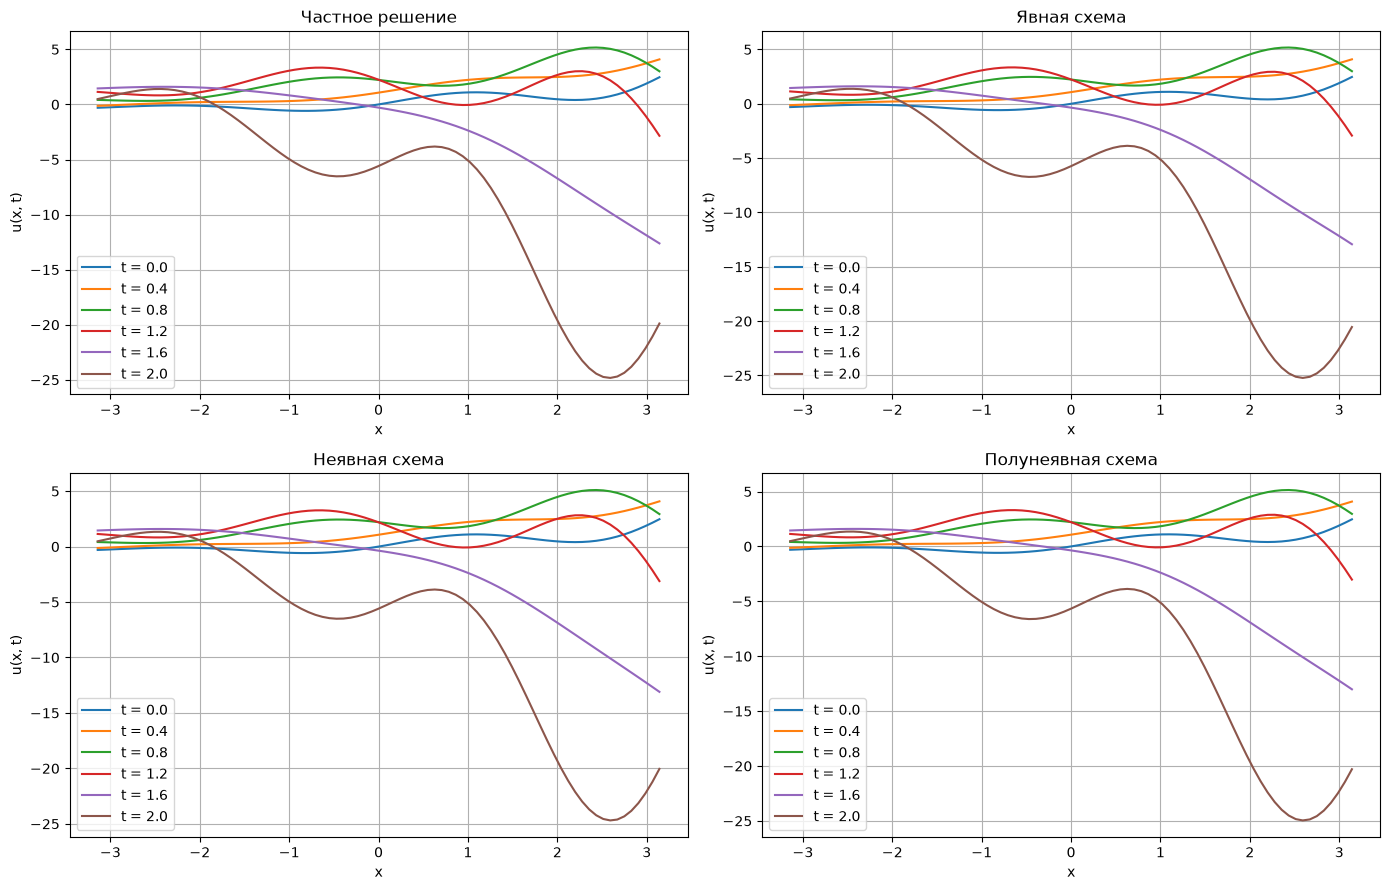

In [7]:
exact_layers = {}
for time in times_to_show:
    exact_layers[time] = [exact_solution(x, time) for x in x_grid]

plots = [
    ('Частное решение', exact_layers),
    ('Явная схема', explicit_layers),
    ('Неявная схема', implicit_layers),
    ('Полунеявная схема', semi_implicit_layers),
]

figure = plt.figure(figsize=(14, 9))

for plot_number, (title, layers) in enumerate(plots, start=1):
    axis = figure.add_subplot(2, 2, plot_number)

    for time in times_to_show:
        axis.plot(x_grid, layers[time], label=f't = {time:.1f}')

    axis.set_title(title)
    axis.set_xlabel('x')
    axis.set_ylabel('u(x, t)')
    axis.grid(True)
    axis.legend()

figure.tight_layout()
plt.show()

## Невязка в различные моменты времени

В узле $x_j$ на слое $t^n$ невязка равна $e_j^n=|u_j^n-U(x_j,t^n)|$. Для каждого слоя вычисляются максимальная и среднеквадратичная нормы:

$$
\|e^n\|_\infty=\max_j e_j^n, \qquad
\|e^n\|_{\mathrm{rms}}=\sqrt{\frac{1}{N+1}\sum_{j=0}^{N}(e_j^n)^2}.
$$

Поскольку норма является одним числом для всего временного слоя, она строится как функция времени. Отдельно показаны максимальная и среднеквадратичная нормы; линии соответствуют разным схемам. Для этих графиков значения вычисляются через $\Delta t=0.02$.

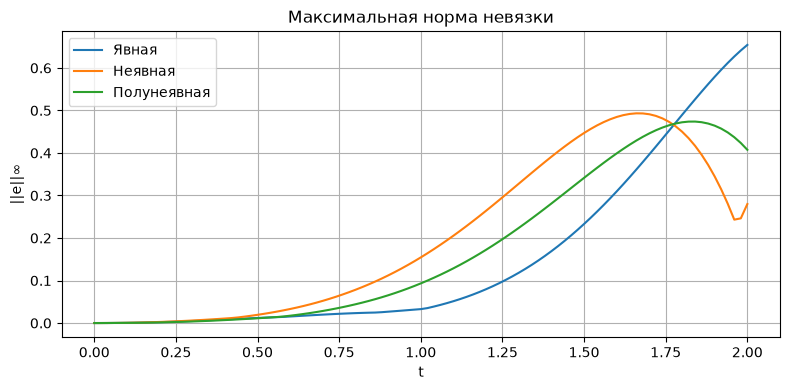

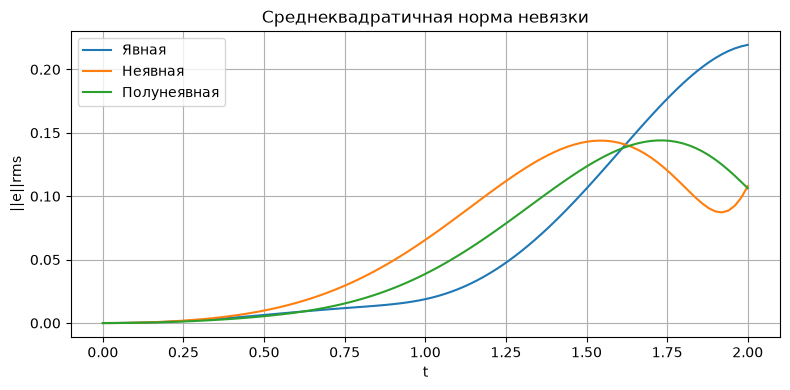

In [8]:
norm_plots = [
    ('Максимальная норма невязки', 0, '||e||∞'),
    ('Среднеквадратичная норма невязки', 1, '||e||rms'),
]

for title, norm_number, y_label in norm_plots:
    figure, axis = plt.subplots(figsize=(8, 4))

    for scheme_name, norms_by_time in error_norms_by_scheme.items():
        norm_values = [norms_by_time[time][norm_number]
                       for time in error_times]
        axis.plot(error_times, norm_values, label=scheme_name)

    axis.set_title(title)
    axis.set_xlabel('t')
    axis.set_ylabel(y_label)
    axis.grid(True)
    axis.legend()
    figure.tight_layout()
    plt.show()

### Вывод

Все три схемы воспроизводят колебания частного решения с возрастающей амплитудой. Неоднородные условия третьего рода учтены со вторым порядком аппроксимации. Для явной схемы выполнено условие Куранта $a\tau/h<1$.